# 04 · Stage 4: the concession measures M1, M1b and M2 (spec §7)

**Gate:**
- spot-check 5 auctions by hand (one short, one medium, one long, one new issue, one from Sept–Oct 2022), with every intermediate value shown;
- distribution plots.

**What Stage 4 delivers**
- `gilt_study.measures`:
  - **M1**: AAY − model yield off the T-1 curve.
  - **M1b**: M1 − the gilt's mean DMO residual over T-25 to T-6.
  - **M2**: the event path T-10 to T+10 with control **B-β** (decision #13). Robustness **B** (β = 1) and the raw path are kept too.
  - The PM's three numbers.
- Outputs in `data/processed_data/measures/`: `auction_measures.csv` (one row per auction), `m2_paths.csv.gz`, `m1b_residuals.csv.gz`. The model-yield cache is in `data/interim_data/`.
- `data/processed_data/measures/handcheck_5_auctions.xlsx`: the five auctions with live formulas. LibreOffice recalculates every one of its 32,145 formulas to the Python result.
- **Not here:** control C (gilt − OIS, from Dec 2021) is a Stage 5 robustness check. So are inference, regressions and the placebo.

**Definitions as built.** Each choice the spec leaves open is marked ⚑ and listed at the gate (§7).

| Measure | Definition |
|---|---|
| Event time | UK business days = BoE curve dates; T = auction date |
| M1 (bp) | 100 × (AAY − model yield), the gilt priced off the **T-1 close** curve. ⚑ Priced for the **auction's settlement date** (DMO issue date), like the AAY. t is measured from that date (first issue date for a new gilt, decision #10) |
| M1b (bp) | M1 − mean over T-25…T-6 of 100 × (DMO reference yield − model yield), both for next-day settlement. ⚑ Days within **±5 business days of an earlier auction** of the same gilt are excluded; ⚑ at least **10 valid days** are needed. Missing for new issues and outside 25 Nov 2002 – 21 Jul 2017 |
| y_k | model yield of the gilt off curve T+k, for settlement on the next business day (the first issue date before launch) |
| Δc_k (B-β) | mean daily change (bp) of the BoE spot points 2.0, 2.5, …, 30.0y lying **more than 3 years** from the gilt's maturity, and present on every day used (≤ 25y before 2016) |
| β | OLS slope of Δy on Δc **with an intercept** (α estimated, not subtracted) over k = −120…−21 (100 changes) |
| AR, CAR | AR_k = Δy_k − β·Δc_k; CAR = 0 at T-6, cumulated forwards and backwards. **B**: β = 1 |
| PM's three numbers ⚑ | pre-auction = CAR(T-1) − CAR(T-6) (the changes of days T-5…T-1); auction day = CAR(T) − CAR(T-1); post-auction = CAR(T+5) − CAR(T). Positive = cheapened against the control |

In [1]:
import datetime as dt
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns

from gilt_study import auctions as au, config, curve, measures as ms, plotting
from gilt_study.exercises import handcheck_stage4 as hc

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 40)
plotting.set_seaborn_theme()

M = ms.load_measures()                       # python -m gilt_study.measures builds these (~4 min, 2 cores)
PTH = pd.read_csv(ms.PATHS_FILE)
RES = pd.read_csv(ms.RESIDUALS_FILE)
P = au.load_auction_panel()
cp = curve.load_panel()
print(f"{len(M)} auctions; M1 for {M.m1_bp.notna().sum()}, M1b for {M.m1b_bp.notna().sum()}, M2 for {M.m2_day_bbeta_bp.notna().sum()}")

912 auctions; M1 for 912, M1b for 309, M2 for 912


## 1. Coverage

In [2]:
print("M1b missing because:")
print(M.m1b_missing_reason.fillna("(available)").str.replace(r"only \d+ valid days.*", "fewer than 10 valid days", regex=True)
      .value_counts().to_string())
print("\nM1b available by financial-year span:", M.loc[M.m1b_bp.notna(), "auction_date"].min(), "to",
      M.loc[M.m1b_bp.notna(), "auction_date"].max())
print("\nM1 settlement choice: |M1 (auction settlement) − M1 (curve's own settlement, T)|, bp:",
      (M.m1_bp - M.m1_alt_curve_settlement_bp).abs().describe()[["mean", "50%", "max"]].round(3).to_dict())

M1b missing because:
m1b_missing_reason
outside the reference-price data      472
(available)                           309
new issue: no prices before launch     80
fewer than 10 valid days               51

M1b available by financial-year span: 2003-01-15 to 2017-07-25

M1 settlement choice: |M1 (auction settlement) − M1 (curve's own settlement, T)|, bp: {'mean': 0.019, '50%': 0.011, 'max': 0.17}


- **M1 and M2 exist for all 912 auctions.**
- **M1b** exists for 309. It is missing for:
  - 472 auctions outside the DMO reference yields (before 25 Nov 2002 or after 21 Jul 2017);
  - 80 new issues;
  - 51 auctions with fewer than 10 valid days. These are mostly the 9-day case: the previous auction of the same gilt fell about 20 business days earlier, so the ±5-day exclusion removes 11 of the 20 days. See the sensitivity check in §4.
- **The M1 settlement choice is immaterial.** Pricing for the curve's own settlement (T) instead of the auction's (T+1) moves M1 by at most 0.17bp.

## 2. Distributions

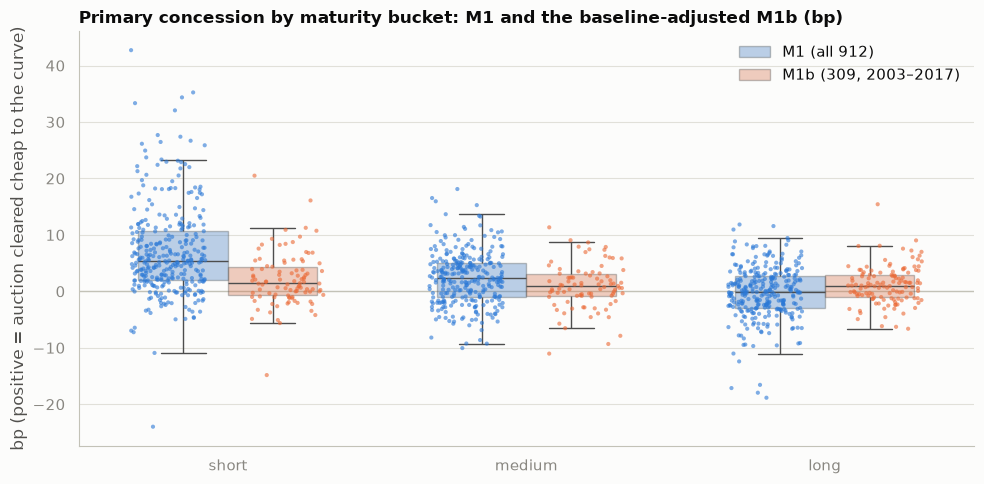

In [3]:
long_ = pd.concat([M[["bucket", "m1_bp"]].rename(columns={"m1_bp": "bp"}).assign(measure="M1 (all 912)"),
                   M[["bucket", "m1b_bp"]].dropna().rename(columns={"m1b_bp": "bp"}).assign(measure="M1b (309, 2003–2017)")])
order = ["short", "medium", "long"]
cm = plotting.colour_map(["M1 (all 912)", "M1b (309, 2003–2017)"])
title = "Primary concession by maturity bucket: M1 and the baseline-adjusted M1b (bp)"

fig_s, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, color=plotting.BASELINE, lw=1)
sns.boxplot(data=long_, x="bucket", y="bp", hue="measure", order=order, palette=cm, fliersize=0, width=0.6,
            linewidth=1, ax=ax, boxprops=dict(alpha=0.35))
sns.stripplot(data=long_, x="bucket", y="bp", hue="measure", order=order, palette=cm, dodge=True, size=3,
              alpha=0.6, jitter=0.25, ax=ax, legend=False)
ax.set_xlabel(""); ax.set_ylabel("bp (positive = auction cleared cheap to the curve)")
ax.set_title(title)
h, l = ax.get_legend_handles_labels(); ax.legend(h[:2], l[:2], title=None, loc="upper right")
fig_s.tight_layout()

fig_p = go.Figure()
for m, colour in cm.items():
    s = long_[long_.measure == m]
    fig_p.add_trace(go.Box(x=s.bucket, y=s.bp, name=m, marker_color=colour, boxpoints="all", jitter=0.4,
                           pointpos=0, marker=dict(size=4, opacity=0.6), line=dict(width=1.5)))
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, boxmode="group", height=480, title=title,
                    yaxis_title="bp", xaxis=dict(categoryorder="array", categoryarray=order),
                    legend=dict(orientation="h", y=-0.15))
plotting.save_pair("m1_m1b_by_bucket", fig_s, fig_p)
fig_p.show()

In [4]:
summ = lambda s: pd.Series({"n": s.notna().sum(), "mean": s.mean(), "median": s.median(), "sd": s.std()})
tab = pd.concat({c: M.groupby("bucket")[c].apply(summ).unstack() for c in
                 ["m1_bp", "m1b_bp", "m2_pre_bbeta_bp", "m2_day_bbeta_bp", "m2_post_bbeta_bp"]}, axis=1)
tab.loc[order].round(2)

m1_bp                    m1b_bp                    m2_pre_bbeta_bp                    m2_day_bbeta_bp                    m2_post_bbeta_bp                   
            n  mean median    sd      n  mean median    sd               n  mean median    sd               n  mean median    sd                n  mean median    sd
bucket                                                                                                                                                              
short   324.0  7.00   5.40  8.04   98.0  2.08   1.42  4.71           324.0  0.45   0.07  7.86           324.0  0.15   0.07  3.48            324.0 -0.68  -0.97  6.65
medium  289.0  2.35   2.36  4.69   86.0  0.91   0.86  4.01           289.0  0.36   0.06  3.50           289.0  0.03  -0.07  1.67            289.0 -0.31  -0.04  3.39
long    299.0 -0.23  -0.13  4.62  125.0  1.14   1.03  3.30           299.0  0.48   0.49  3.87           299.0 -0.08  -0.07  1.73            299.0 -0.28  -0.19  3.42

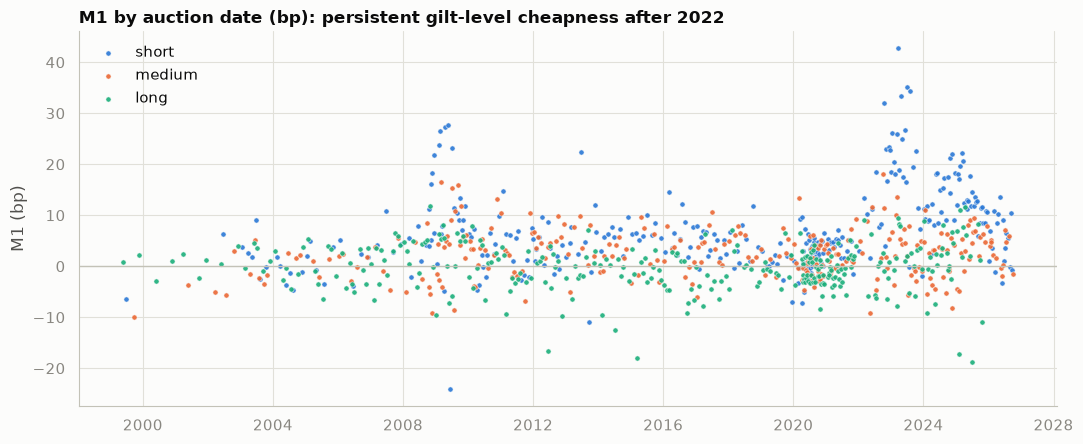

In [5]:
M["auction_ts"] = pd.to_datetime(M.auction_date)
cb = plotting.colour_map(order)
title = "M1 by auction date (bp): persistent gilt-level cheapness after 2022"
fig_s, ax = plt.subplots(figsize=(11, 4.6))
ax.axhline(0, color=plotting.BASELINE, lw=1)
for b in order:
    s = M[M.bucket == b]
    ax.scatter(s.auction_ts, s.m1_bp, s=14, color=cb[b], label=b, edgecolor=plotting.SURFACE, linewidth=0.4, alpha=0.9)
ax.set_ylabel("M1 (bp)"); ax.set_title(title); ax.legend(title=None, loc="upper left")
fig_s.tight_layout()
fig_p = go.Figure()
for b in order:
    s = M[M.bucket == b]
    fig_p.add_trace(go.Scatter(x=s.auction_ts, y=s.m1_bp, mode="markers", name=b,
                               marker=dict(color=cb[b], size=7, line=dict(color=plotting.SURFACE, width=1)),
                               customdata=np.stack([s.gilt_name, s.regime], axis=1),
                               hovertemplate="%{customdata[0]}<br>%{x|%d %b %Y} (%{customdata[1]})<br>M1 %{y:+.1f} bp<extra></extra>"))
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=440, title=title, yaxis_title="M1 (bp)",
                    legend=dict(orientation="h", y=-0.2))
plotting.save_pair("m1_over_time", fig_s, fig_p)
fig_p.show()

### A finding about M1 after 2017: much of it is the gilt, not the auction

M1 compares the auction yield with a smooth curve, so a gilt that always trades cheap to the curve shows a positive M1 at every auction. This is why decision #4 introduced M1b. M1b cannot be computed after July 2017, because there are no free bond prices.

The cell below measures how much of M1 is fixed per gilt. It uses gilts auctioned more than once and computes the share of M1's variance that the gilt's own mean explains.

In [6]:
M["yr"] = M.auction_ts.dt.year
def gilt_share(s):
    multi = s[s.groupby("isin")["m1_bp"].transform("size") > 1]
    resid = multi.m1_bp - multi.groupby("isin")["m1_bp"].transform("mean")
    return pd.Series({"auctions": len(multi), "gilts": multi["isin"].nunique(),
                      "share of M1 variance explained by the gilt": 1 - (resid ** 2).sum() / ((multi.m1_bp - multi.m1_bp.mean()) ** 2).sum()})
print(pd.DataFrame({"1999–2017": gilt_share(M[M.yr <= 2017]), "2018–2026": gilt_share(M[M.yr >= 2018])}).round(3))
print("\nM1 vs M1b where both exist: correlation", round(M[["m1_bp", "m1b_bp"]].dropna().corr().iloc[0, 1], 3))
M[M["isin"].isin(["GB00BL6C7720", "GB00BPCJD880"])][["auction_date", "gilt_name", "m1_bp", "m2_day_bbeta_bp"]].round(2)

                                            1999–2017  2018–2026
auctions                                      426.000    478.000
gilts                                          57.000     60.000
share of M1 variance explained by the gilt      0.478      0.691

M1 vs M1b where both exist: correlation 0.565


,auction_date,gilt_name,m1_bp,m2_day_bbeta_bp
698,2022-10-12,4 1/8% Treasury Gilt 2027,32.06,-14.85
703,2022-11-10,4 1/8% Treasury Gilt 2027,22.96,-2.99
709,2022-12-06,4 1/8% Treasury Gilt 2027,23.35,-2.02
712,2023-01-05,4 1/8% Treasury Gilt 2027,18.54,0.23
714,2023-01-17,3½% Treasury Gilt 2025,26.15,0.68
716,2023-02-07,4 1/8% Treasury Gilt 2027,20.52,3.65
722,2023-03-07,3½% Treasury Gilt 2025,25.88,6.78
726,2023-03-22,4 1/8% Treasury Gilt 2027,42.73,15.13
731,2023-04-19,4 1/8% Treasury Gilt 2027,33.34,5.51
732,2023-05-03,3½% Treasury Gilt 2025,24.94,0.41


**Reading it.**
- After 2017 the gilt's own mean explains **69%** of M1's variance, against 48% before.
- The largest M1 values belong to the same two short gilts at auction after auction: 4⅛% 2027 (17–43bp over 9 auctions) and 3½% 2025 (7–35bp). These are level effects of the gilt, not concessions.
- On the same auctions, M2 (a change over the auction) is mostly small. M2 does not see levels.
- So, **for 2018–2026, M1 levels need the gilt's persistent cheapness removed** before they can be read as concessions. This is a decision for you (§7).

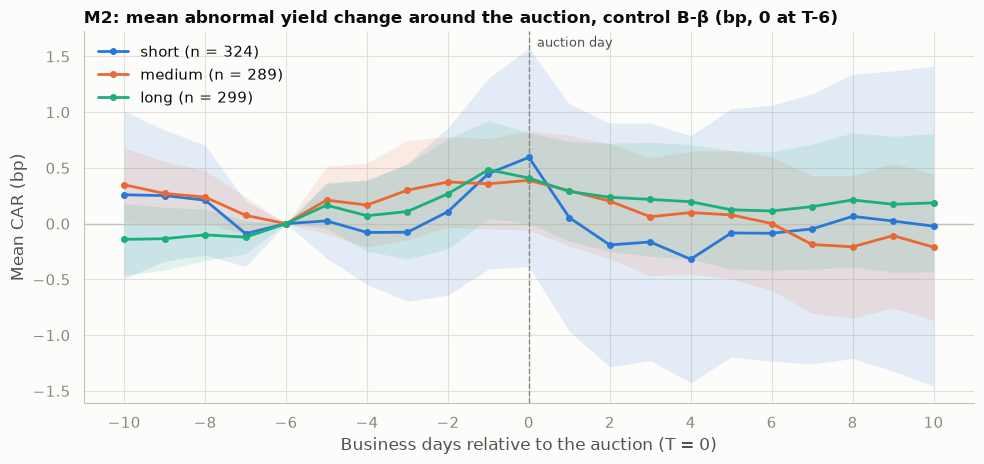

In [7]:
car = PTH.merge(M[["auction_id", "bucket"]], on="auction_id")
agg = car.groupby(["bucket", "k"])["car_bbeta"].agg(mean="mean", se=lambda s: s.std() / np.sqrt(len(s)), n="size").reset_index()
agg["lo"], agg["hi"] = agg["mean"] - 1.96 * agg["se"], agg["mean"] + 1.96 * agg["se"]
title = "M2: mean abnormal yield change around the auction, control B-β (bp, 0 at T-6)"

fig_s, ax = plt.subplots(figsize=(10, 4.8))
ax.axhline(0, color=plotting.BASELINE, lw=1)
ax.axvline(0, color=plotting.INK_MUTED, lw=1, ls="--")
for b in order:
    a = agg[agg.bucket == b]
    ax.fill_between(a.k, a.lo, a.hi, color=cb[b], alpha=0.12, lw=0)
    ax.plot(a.k, a["mean"], color=cb[b], label=f"{b} (n = {int(a.n.iloc[0])})", marker="o", ms=4)
ax.set_xlabel("Business days relative to the auction (T = 0)"); ax.set_ylabel("Mean CAR (bp)")
ax.set_title(title); ax.legend(title=None, loc="upper left")
ax.set_xticks(range(-10, 11, 2))
ax.text(0.2, ax.get_ylim()[1] * 0.92, "auction day", color=plotting.INK_SECONDARY, fontsize=9)
fig_s.tight_layout()

fig_p = go.Figure()
for b in order:
    a = agg[agg.bucket == b]
    r_, g_, b_ = (int(cb[b][i:i + 2], 16) for i in (1, 3, 5))
    fig_p.add_trace(go.Scatter(x=np.r_[a.k, a.k[::-1]], y=np.r_[a.hi, a.lo[::-1]], fill="toself",
                               fillcolor=f"rgba({r_},{g_},{b_},0.12)", line=dict(width=0), hoverinfo="skip",
                               showlegend=False, legendgroup=b))
    fig_p.add_trace(go.Scatter(x=a.k, y=a["mean"], mode="lines+markers", name=f"{b} (n = {int(a.n.iloc[0])})",
                               legendgroup=b, line=dict(color=cb[b]), marker=dict(size=6),
                               customdata=np.stack([a.lo, a.hi], axis=1),
                               hovertemplate="T%{x:+d}: %{y:+.2f} bp<br>95% band %{customdata[0]:+.2f} to %{customdata[1]:+.2f}<extra>" + b + "</extra>"))
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.add_vline(x=0, line_dash="dash", line_color=plotting.INK_MUTED)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=460, title=title,
                    xaxis_title="Business days relative to the auction (T = 0)", yaxis_title="Mean CAR (bp)",
                    legend=dict(orientation="h", y=-0.2))
plotting.save_pair("m2_car_paths", fig_s, fig_p)
fig_p.show()

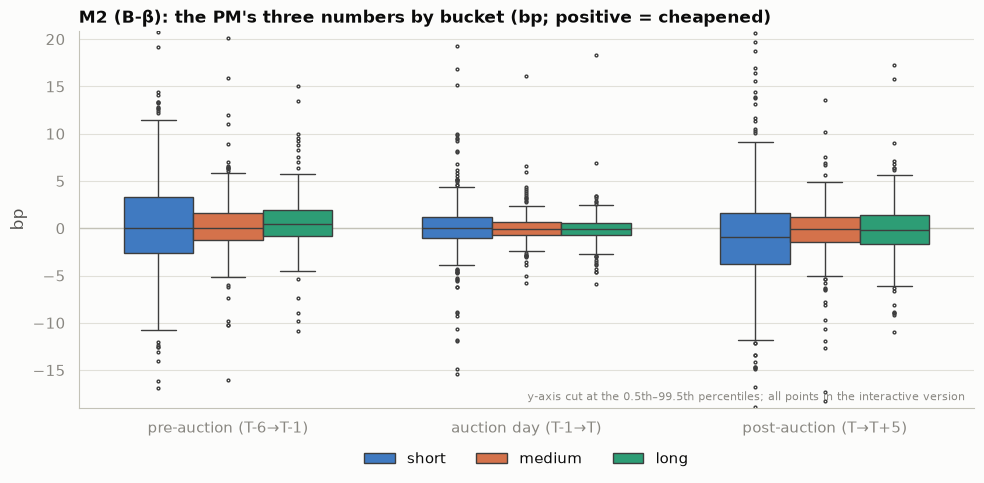

In [8]:
pm = M.melt(id_vars=["bucket"], value_vars=["m2_pre_bbeta_bp", "m2_day_bbeta_bp", "m2_post_bbeta_bp"],
            var_name="window", value_name="bp")
names = {"m2_pre_bbeta_bp": "pre-auction (T-6→T-1)", "m2_day_bbeta_bp": "auction day (T-1→T)",
         "m2_post_bbeta_bp": "post-auction (T→T+5)"}
pm["window"] = pm.window.map(names)
title = "M2 (B-β): the PM's three numbers by bucket (bp; positive = cheapened)"
fig_s, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, color=plotting.BASELINE, lw=1)
sns.boxplot(data=pm, x="window", y="bp", hue="bucket", hue_order=order, palette=cb, fliersize=2, width=0.7,
            linewidth=1, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("bp"); ax.set_title(title)
ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=3)
ax.set_ylim(np.nanpercentile(pm.bp, 0.5) - 2, np.nanpercentile(pm.bp, 99.5) + 2)
ax.text(0.99, 0.02, "y-axis cut at the 0.5th–99.5th percentiles; all points in the interactive version",
        transform=ax.transAxes, ha="right", fontsize=8, color=plotting.INK_MUTED)
fig_s.tight_layout()
fig_p = go.Figure()
for b in order:
    s = pm[pm.bucket == b]
    fig_p.add_trace(go.Box(x=s.window, y=s.bp, name=b, marker_color=cb[b], boxpoints="outliers", line=dict(width=1.5)))
fig_p.add_hline(y=0, line_color=plotting.BASELINE)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, boxmode="group", height=480, title=title, yaxis_title="bp",
                    legend=dict(orientation="h", y=-0.15))
plotting.save_pair("m2_pm_numbers", fig_s, fig_p)
fig_p.show()

bucket        short   medium     long
beta count  324.000  289.000  299.000
     mean     0.877    1.052    1.000
     std      0.211    0.117    0.118
     min      0.403    0.731    0.668
     25%      0.714    1.002    0.935
     50%      0.906    1.071    0.982
     75%      1.011    1.127    1.068
     max      1.424    1.386    1.256
r2   count  324.000  289.000  299.000
     mean     0.788    0.952    0.940
     std      0.104    0.033    0.041
     min      0.456    0.799    0.787
     25%      0.724    0.939    0.920
     50%      0.804    0.958    0.951
     75%      0.870    0.976    0.972
     max      0.947    0.996    0.995
β outliers (β < 0 or β > 3): 0


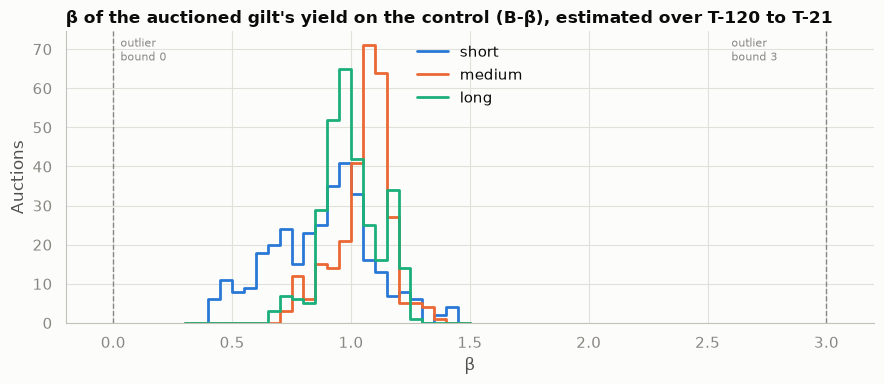

In [9]:
title = "β of the auctioned gilt's yield on the control (B-β), estimated over T-120 to T-21"
fig_s, ax = plt.subplots(figsize=(9, 4))
for b in order:
    sns.histplot(M[M.bucket == b].beta, bins=np.arange(0.3, 1.55, 0.05), color=cb[b], label=b, element="step",
                 fill=False, linewidth=2, ax=ax)
for x in ms.BETA_OUTLIER:
    ax.axvline(x, color=plotting.INK_MUTED, ls="--", lw=1)
ax.set_xlim(-0.2, 3.2); ax.set_xlabel("β"); ax.set_ylabel("Auctions"); ax.set_title(title); ax.legend(title=None)
ax.text(0.03, ax.get_ylim()[1] * 0.9, "outlier\nbound 0", fontsize=8, color=plotting.INK_MUTED)
ax.text(2.6, ax.get_ylim()[1] * 0.9, "outlier\nbound 3", fontsize=8, color=plotting.INK_MUTED)
fig_s.tight_layout()
fig_p = go.Figure()
for b in order:
    fig_p.add_trace(go.Histogram(x=M[M.bucket == b].beta, name=b, xbins=dict(start=0.3, end=1.55, size=0.05),
                                 marker_color=cb[b], opacity=0.55))
for x in ms.BETA_OUTLIER:
    fig_p.add_vline(x=x, line_dash="dash", line_color=plotting.INK_MUTED)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, barmode="overlay", height=400, title=title,
                    xaxis=dict(title="β", range=[-0.2, 3.2]), yaxis_title="Auctions", legend=dict(orientation="h", y=-0.2))
plotting.save_pair("m2_beta_distribution", fig_s, fig_p)
fig_p.show()
print(M.groupby("bucket")[["beta", "r2"]].describe().round(3).loc[order].T)
print("β outliers (β < 0 or β > 3):", int(M.beta_outlier.sum()))

- **β:** every β lies between 0.40 and 1.42, so there are **no outliers** (spec: β < 0 or > 3). The median is about 1, and the median R² is 0.93. The control tracks the gilt closely, as it should in a curve-based measure.
- **M2 averages** are small: the pre-auction and auction-day means are within about ±0.5bp. The LDI window is the exception. The regime split and inference are Stage 5.

In [10]:
reg = M.groupby("regime")[["m1_bp", "m1b_bp", "m2_pre_bbeta_bp", "m2_day_bbeta_bp", "m2_post_bbeta_bp"]].agg(["mean", "count"]).round(2)
reg.loc[["pre-crisis", "QE", "LDI stress", "active QT", "post-QT-decision"]]

m1_bp       m1b_bp       m2_pre_bbeta_bp       m2_day_bbeta_bp       m2_post_bbeta_bp      
                   mean count   mean count            mean count            mean count             mean count
regime                                                                                                       
pre-crisis         1.31   129   2.65    89            1.13   129           -0.05   129            -0.88   129
QE                 2.11   570   0.86   220            0.59   570           -0.04   570            -0.62   570
LDI stress        17.62     3    NaN     0          -18.26     3            0.12     3             5.00     3
active QT          6.99   208    NaN     0           -0.16   208            0.32   208             0.28   208
post-QT-decision  -1.13     2    NaN     0            1.48     2           -1.73     2            -1.43     2

## 3. M2 robustness B (β = 1) against B-β

In [11]:
for w in ["pre", "day", "post"]:
    a, b = M[f"m2_{w}_bbeta_bp"], M[f"m2_{w}_b_bp"]
    print(f"{w:4s}: corr {np.corrcoef(a, b)[0, 1]:.3f} | mean B-β {a.mean():+.2f} vs B {b.mean():+.2f} | "
          f"median |diff| {(a - b).abs().median():.2f} bp")

pre : corr 0.955 | mean B-β +0.43 vs B +0.40 | median |diff| 0.53 bp
day : corr 0.951 | mean B-β +0.04 vs B +0.02 | median |diff| 0.25 bp
post: corr 0.944 | mean B-β -0.43 vs B -0.49 | median |diff| 0.59 bp


## 4. M1b sensitivity to the two defaults (⚑)

These are the proposed defaults: exclude ±5 business days around an earlier auction of the same gilt, and require at least 10 valid days. The table recomputes M1b under alternatives from the stored daily residuals.

In [12]:
pos = {d: i for i, d in enumerate(cp.index.date)}
auc_by_isin = P.groupby("isin")["auction_date"].apply(sorted).to_dict()
R = RES.copy()
R["date"] = [dt.date.fromisoformat(v) for v in R["date"]]
R["isin"] = R.auction_id.str.split("_").str[1]
R["T"] = [dt.date.fromisoformat(a.split("_")[0]) for a in R.auction_id]
R["dist"] = [min([abs(pos[d] - pos[x]) for x in auc_by_isin[i] if x < t] or [999]) for d, i, t in zip(R["date"], R["isin"], R["T"])]
other = R.excluded.notna() & ~R.excluded.fillna("").str.startswith("within 5")
rows = []
for excl in [5, 2, 0, -1]:
    for mind in [10, 5]:
        ok = R.residual_bp.notna() & ~other & (R.dist > excl)
        b = R[ok].groupby("auction_id").residual_bp.agg(["mean", "size"])
        b = b[b["size"] >= mind]
        m = M.set_index("auction_id").loc[b.index]
        v = m.m1_bp - b["mean"]
        rows.append(dict(exclude_around_earlier_auction="none" if excl < 0 else f"±{excl} days", min_days=mind,
                         auctions=len(v), mean_m1b=v.mean(), median_m1b=v.median()))
pd.DataFrame(rows).round(2)

,exclude_around_earlier_auction,min_days,auctions,mean_m1b,median_m1b
0,±5 days,10,309,1.37,1.04
1,±5 days,5,352,1.30,0.97
2,±2 days,10,356,1.27,0.97
3,±2 days,5,359,1.28,0.97
4,±0 days,10,359,1.27,0.96
5,±0 days,5,359,1.27,0.96
6,none,10,359,1.27,0.96
7,none,5,359,1.27,0.96


Looser rules raise coverage from 309 to 352–359 auctions. The mean M1b moves only from 1.37 to 1.27–1.30bp, and the median from 1.04 to about 0.97bp. The choice matters for coverage, not for the level.

## 5. The five hand-check auctions

| Slot | Auction | Why this one |
|---|---|---|
| **A1 short** | 6 Aug 2013, 1¼% Treasury Gilt 2018 | short reopening, 2010–2016, M1b available, M1 closest to the short-bucket median |
| **A2 medium** | 21 Oct 2010, 3¾% Treasury Gilt 2020 | same rule, medium bucket. 6 days fall near its previous auction, so M1b uses 14 days and shows the exclusion rule |
| **A3 long** | 9 Oct 2012, 4¼% Treasury Stock 2032 | same rule, long bucket, within the 25y curve |
| **A4 new issue** | 15 Mar 2018, 1⅝% Treasury Gilt 2028 | a new issue with a **long first coupon** (22 Oct 2018, from the DMO prospectus) and when-issued pricing from the first issue date |
| **A5 Sept–Oct 2022** | 4 Oct 2022, 0½% Treasury Gilt 2061 | LDI stress window, ultra-long (38.8y, inside the 40y curve) |

The rule used to pick them is in `handcheck_stage4.choose()`, applied to the built measures. Below, for each auction:
- the full M1 calculation (every cash flow, z, discount factor and PV, the dirty price, the model yield and its re-pricing);
- the M1b residual table;
- the β estimate and the T-10…T+10 path.

The workbook has the same numbers with live formulas, plus the 100 β-window days and every control maturity's daily z.

In [13]:
picks = hc.choose(M, P)
J = M.merge(P[["auction_date", "isin", "coupon", "maturity", "first_issue", "first_coupon", "first_coupon_source"]],
            on=["auction_date", "isin"])
J["first_issue"] = [v if isinstance(v, dt.date) else None for v in J["first_issue"]]
J["first_coupon"] = [v if isinstance(v, dt.date) else None for v in J["first_coupon"]]
rows = {slot: next(J[J.auction_id == aid].itertuples(index=False)) for slot, aid in picks.items()}


def show(slot):
    r = rows[slot]
    T, o = hc.m1_table(r, cp)
    print(f"=== {slot}: {r.gilt_name}, auction {r.auction_date} (settles {r.settlement_date}); bucket {r.bucket}, regime {r.regime}")
    print(f"coupon {r.coupon}%, maturity {r.maturity}, first issue {r.first_issue}, first coupon {r.first_coupon} ({r.first_coupon_source})")
    print(f"M1: T-1 curve {o['curve_date']} (last maturity {o['t_max']:.0f}y); priced for {o['effective_settlement']}")
    print(f"    curve dirty {o['dirty']:.6f} - accrued {o['accrued']:.6f} = clean {o['clean']:.6f}")
    print(f"    model yield {o['model_yield']:.6f}% (price at that yield {o['price_at_model_yield']:.6f}); "
          f"AAY {o['aay']:.6f}% -> M1 = {o['m1_bp']:+.4f} bp")
    return T


def show_m1b(slot):
    r = rows[slot]
    x = RES[RES.auction_id == r.auction_id][["k", "date", "dmo_yield", "model_yield", "residual_bp", "excluded"]]
    print(f"M1b: baseline {r.m1b_baseline_bp:.4f} bp over {r.m1b_days} valid days -> M1b = {r.m1b_bp:+.4f} bp"
          if pd.notna(r.m1b_bp) else f"M1b: missing ({r.m1b_missing_reason})")
    return x


def show_m2(slot):
    r = rows[slot]
    print(f"M2: β = {r.beta:.4f} (α {r.alpha_bp:+.4f} bp, se {r.se_beta:.4f}, R² {r.r2:.3f}, n {r.n_beta}); "
          f"control = {r.n_control_maturities} BoE points from {r.control_min:g} to {r.control_max:g}y, excluding ±3y of {r.years_to_maturity:.2f}y")
    print(f"    pre {r.m2_pre_bbeta_bp:+.3f} | day {r.m2_day_bbeta_bp:+.3f} | post {r.m2_post_bbeta_bp:+.3f} bp (B-β);  "
          f"B: {r.m2_pre_b_bp:+.3f} / {r.m2_day_b_bp:+.3f} / {r.m2_post_b_bp:+.3f}")
    return PTH[PTH.auction_id == r.auction_id].drop(columns="auction_id")

### A1 · short

In [14]:
show("short")

=== short: 1¼% Treasury Gilt 2018, auction 2013-08-06 (settles 2013-08-07); bucket short, regime QE
coupon 1.25%, maturity 2018-07-22, first issue 2013-02-15, first coupon 2013-07-22 (DMO reference prices (accrued interest))
M1: T-1 curve 2013-08-05 (last maturity 25y); priced for 2013-08-07
    curve dirty 99.537106 - accrued 0.054348 = clean 99.482758
    model yield 1.358227% (price at that yield 99.537106); AAY 1.405044% -> M1 = +4.6817 bp


,cash_flow_date,amount,t_years,z_pct,beyond_curve,df,pv,expo,pv_at_model_yield
0,2014-01-22,0.625,0.459959,0.335309,False,0.998459,0.624037,0.913043,0.621150
1,2014-07-22,0.625,0.955510,0.297862,False,0.997158,0.623224,1.913043,0.616960
2,2015-01-22,0.625,1.459274,0.312826,False,0.995445,0.622153,2.913043,0.612798
3,2015-07-22,0.625,1.954825,0.400970,False,0.992192,0.620120,3.913043,0.608665
4,2016-01-22,0.625,2.458590,0.536014,False,0.986908,0.616818,4.913043,0.604559
5,2016-07-22,0.625,2.956879,0.693249,False,0.979710,0.612319,5.913043,0.600481
6,2017-01-22,0.625,3.460643,0.862884,False,0.970580,0.606613,6.913043,0.596431
7,2017-07-22,0.625,3.956194,1.032883,False,0.959961,0.599975,7.913043,0.592408
8,2018-01-22,0.625,4.459959,1.204644,False,0.947691,0.592307,8.913043,0.588412
9,2018-07-22,100.625,4.955510,1.370154,False,0.934356,94.019541,9.913043,94.095244


In [15]:
show_m1b("short")

M1b: baseline 1.4811 bp over 20 valid days -> M1b = +3.2006 bp


,k,date,dmo_yield,model_yield,residual_bp,excluded
5960,-25,2013-07-02,1.385677,1.360957,2.472011,NaN
5961,-24,2013-07-03,1.416750,1.390003,2.674652,NaN
5962,-23,2013-07-04,1.367240,1.350203,1.703677,NaN
5963,-22,2013-07-05,1.435774,1.420539,1.523499,NaN
5964,-21,2013-07-08,1.413053,1.400426,1.262684,NaN
5965,-20,2013-07-09,1.346877,1.335085,1.179173,NaN
5966,-19,2013-07-10,1.351066,1.332143,1.892331,NaN
5967,-18,2013-07-11,1.324276,1.304827,1.944851,NaN
5968,-17,2013-07-12,1.287164,1.261149,2.601470,NaN
5969,-16,2013-07-15,1.301656,1.278830,2.282618,NaN


In [16]:
show_m2("short")

M2: β = 0.9138 (α -0.0353 bp, se 0.0486, R² 0.783, n 100); control = 35 BoE points from 8 to 25y, excluding ±3y of 4.96y
    pre +4.483 | day +1.096 | post +1.064 bp (B-β);  B: +3.641 / +1.109 / +0.130


,k,curve_date,model_yield,dy_bp,dc_bp,ar_bbeta,car_bbeta,ar_b,car_b,car_raw
6258,-10,2013-07-23,1.236254,4.073778,4.492913,-0.031833,2.437853,-0.419135,2.562408,1.117500
6259,-9,2013-07-24,1.300096,6.384173,6.523139,0.423347,2.861201,-0.138965,2.423443,7.501673
6260,-8,2013-07-25,1.288277,-1.181831,-1.122406,-0.156179,2.705021,-0.059425,2.364018,6.319842
6261,-7,2013-07-26,1.222858,-6.541908,-3.514268,-3.330579,-0.625558,-3.027640,-0.663622,-0.222066
6262,-6,2013-07-29,1.225079,0.222066,-0.441556,0.625558,0.000000,0.663622,0.000000,0.000000
6263,-5,2013-07-30,1.215077,-1.000244,-0.831347,-0.240561,-0.240561,-0.168897,-0.168897,-1.000244
6264,-4,2013-07-31,1.231071,1.599408,2.539143,-0.720854,-0.961415,-0.939735,-1.108631,0.599164
6265,-3,2013-08-01,1.261193,3.012222,2.876920,0.383301,-0.578114,0.135303,-0.973329,3.611387
6266,-2,2013-08-02,1.299596,3.840290,1.216459,2.728693,2.150580,2.623831,1.650503,7.451677
6267,-1,2013-08-05,1.359122,5.952644,3.962201,2.331995,4.482575,1.990443,3.640945,13.404321


### A2 · medium

In [17]:
show("medium")

=== medium: 3¾% Treasury Gilt 2020, auction 2010-10-21 (settles 2010-10-22); bucket medium, regime QE
coupon 3.75%, maturity 2020-09-07, first issue 2010-06-10, first coupon 2010-09-07 (DMO reference prices (accrued interest))
M1: T-1 curve 2010-10-20 (last maturity 25y); priced for 2010-10-22
    curve dirty 106.537809 - accrued 0.466160 = clean 106.071648
    model yield 3.033580% (price at that yield 106.537809); AAY 3.055442% -> M1 = +2.1862 bp


,cash_flow_date,amount,t_years,z_pct,beyond_curve,df,pv,expo,pv_at_model_yield
0,2011-03-07,1.875,0.372348,0.543134,False,0.997980,1.871212,0.751381,1.853911
1,2011-09-07,1.875,0.876112,0.567440,False,0.995041,1.865702,1.751381,1.826211
2,2012-03-07,1.875,1.374401,0.607687,False,0.991683,1.859405,2.751381,1.798925
3,2012-09-07,1.875,1.878166,0.696772,False,0.986999,1.850623,3.751381,1.772047
4,2013-03-07,1.875,2.373717,0.824324,False,0.980623,1.838668,4.751381,1.745570
5,2013-09-07,1.875,2.877481,0.981998,False,0.972139,1.822760,5.751381,1.719489
6,2014-03-07,1.875,3.373032,1.153912,False,0.961826,1.803424,6.751381,1.693798
7,2014-09-07,1.875,3.876797,1.337462,False,0.949471,1.780257,7.751381,1.668490
8,2015-03-07,1.875,4.372348,1.521014,False,0.935659,1.754361,8.751381,1.643561
9,2015-09-07,1.875,4.876112,1.706777,False,0.920145,1.725271,9.751381,1.619004


In [18]:
show_m1b("medium")

M1b: baseline 5.4827 bp over 14 valid days -> M1b = -3.2965 bp


,k,date,dmo_yield,model_yield,residual_bp,excluded
4180,-25,2010-09-16,3.247579,3.204508,4.307064,within 5 business days of an earlier auction o...
4181,-24,2010-09-17,3.233365,3.189485,4.388012,within 5 business days of an earlier auction o...
4182,-23,2010-09-20,3.258637,3.217038,4.159881,within 5 business days of an earlier auction o...
4183,-22,2010-09-21,3.221585,3.179636,4.194911,within 5 business days of an earlier auction o...
4184,-21,2010-09-22,3.073872,3.029925,4.394743,within 5 business days of an earlier auction o...
4185,-20,2010-09-23,3.058949,3.008257,5.069206,within 5 business days of an earlier auction o...
4186,-19,2010-09-24,3.154261,3.096774,5.748724,NaN
4187,-18,2010-09-27,3.084436,3.028689,5.574735,NaN
4188,-17,2010-09-28,3.041095,2.986646,5.444885,NaN
4189,-16,2010-09-29,3.018266,2.961364,5.690163,NaN


In [19]:
show_m2("medium")

M2: β = 1.0419 (α -0.3167 bp, se 0.0299, R² 0.925, n 100); control = 35 BoE points from 2 to 25y, excluding ±3y of 9.88y
    pre -0.192 | day +0.066 | post +1.542 bp (B-β);  B: +0.233 / -0.149 / +2.345


,k,curve_date,model_yield,dy_bp,dc_bp,ar_bbeta,car_bbeta,ar_b,car_b,car_raw
4389,-10,2010-10-07,2.979212,3.057502,2.885058,0.051516,4.554670,0.172444,4.568243,4.892067
4390,-9,2010-10-08,2.913602,-6.560935,-5.072137,-1.276199,3.278472,-1.488798,3.079445,-1.668868
4391,-8,2010-10-11,2.933376,1.977336,3.542439,-1.713585,1.564887,-1.565103,1.514343,0.308468
4392,-7,2010-10-12,2.897857,-3.551859,-1.716439,-1.763475,-0.198588,-1.835420,-0.321078,-3.243391
4393,-6,2010-10-13,2.930291,3.243391,2.922314,0.198588,0.000000,0.321078,0.000000,0.000000
4394,-5,2010-10-14,2.929983,-0.030814,0.131350,-0.167670,-0.167670,-0.162164,-0.162164,-0.030814
4395,-4,2010-10-15,2.992580,6.259774,7.122492,-1.161258,-1.328928,-0.862718,-1.024882,6.228960
4396,-3,2010-10-18,3.012923,2.034301,1.158055,0.827706,-0.501222,0.876246,-0.148636,8.263260
4397,-2,2010-10-19,3.051078,3.815450,3.952850,-0.303085,-0.804307,-0.137400,-0.286037,12.078710
4398,-1,2010-10-20,3.034097,-1.698140,-2.217470,0.612275,-0.192032,0.519330,0.233293,10.380570


### A3 · long

In [20]:
show("long")

=== long: 4¼% Treasury Stock 2032, auction 2012-10-09 (settles 2012-10-10); bucket long, regime QE
coupon 4.25%, maturity 2032-06-07, first issue 2000-05-25, first coupon 2000-12-07 (DMO reference prices (accrued interest))
M1: T-1 curve 2012-10-08 (last maturity 25y); priced for 2012-10-10
    curve dirty 125.818015 - accrued 1.451503 = clean 124.366513
    model yield 2.651340% (price at that yield 125.818015); AAY 2.661455% -> M1 = +1.0115 bp


,cash_flow_date,amount,t_years,z_pct,beyond_curve,df,pv,expo,pv_at_model_yield
0,2012-12-07,2.125,0.158795,0.443729,False,0.999296,2.123503,0.31694,2.116149
1,2013-06-07,2.125,0.657084,0.348532,False,0.997712,2.120139,1.31694,2.088463
2,2013-12-07,2.125,1.158111,0.245145,False,0.997165,2.118976,2.31694,2.061139
3,2014-06-07,2.125,1.656400,0.186282,False,0.996919,2.118453,3.31694,2.034172
4,2014-12-07,2.125,2.157426,0.186760,False,0.995979,2.116455,4.31694,2.007559
5,2015-06-07,2.125,2.655715,0.229862,False,0.993914,2.112067,5.31694,1.981293
6,2015-12-07,2.125,3.156742,0.301651,False,0.990523,2.104861,6.31694,1.955372
7,2016-06-07,2.125,3.657769,0.391987,False,0.985764,2.094749,7.31694,1.929789
8,2016-12-07,2.125,4.158795,0.494001,False,0.979665,2.081788,8.31694,1.904541
9,2017-06-07,2.125,4.657084,0.602405,False,0.972335,2.066213,9.31694,1.879623


In [21]:
show_m1b("long")

M1b: baseline -0.5033 bp over 20 valid days -> M1b = +1.5149 bp


,k,date,dmo_yield,model_yield,residual_bp,excluded
5520,-25,2012-09-04,2.499266,2.493772,0.549398,NaN
5521,-24,2012-09-05,2.515781,2.522845,-0.706401,NaN
5522,-23,2012-09-06,2.597495,2.599990,-0.249524,NaN
5523,-22,2012-09-07,2.577860,2.577095,0.076496,NaN
5524,-21,2012-09-10,2.632029,2.632477,-0.044804,NaN
5525,-20,2012-09-11,2.647255,2.651280,-0.402495,NaN
5526,-19,2012-09-12,2.709606,2.711245,-0.163937,NaN
5527,-18,2012-09-13,2.672108,2.682578,-1.046980,NaN
5528,-17,2012-09-14,2.798563,2.816995,-1.843195,NaN
5529,-16,2012-09-17,2.761051,2.772123,-1.107186,NaN


In [22]:
show_m2("long")

M2: β = 0.9916 (α -0.0280 bp, se 0.0216, R² 0.956, n 100); control = 35 BoE points from 2 to 25y, excluding ±3y of 19.66y
    pre +1.696 | day -0.870 | post -1.501 bp (B-β);  B: +1.692 / -0.864 / -1.575


,k,curve_date,model_yield,dy_bp,dc_bp,ar_bbeta,car_bbeta,ar_b,car_b,car_raw
5796,-10,2012-09-25,2.684221,-1.145662,-0.356938,-0.791740,-1.132253,-0.788724,-1.187955,5.405132
5797,-9,2012-09-26,2.576344,-10.787657,-11.097776,0.216359,-0.915894,0.310118,-0.877836,-5.382525
5798,-8,2012-09-27,2.622332,4.598773,3.883039,0.748540,-0.167354,0.715734,-0.162102,-0.783753
5799,-7,2012-09-28,2.625105,0.277333,-0.311608,0.586308,0.418954,0.588941,0.426839,-0.506420
5800,-6,2012-10-01,2.630170,0.506420,0.933259,-0.418954,0.000000,-0.426839,0.000000,0.000000
5801,-5,2012-10-02,2.616017,-1.415246,-1.987109,0.555075,0.555075,0.571863,0.571863,-1.415246
5802,-4,2012-10-03,2.599178,-1.683934,-2.145145,0.443088,0.998163,0.461211,1.033074,-3.099180
5803,-3,2012-10-04,2.612246,1.306807,1.461894,-0.142736,0.855427,-0.155087,0.877987,-1.792373
5804,-2,2012-10-05,2.682483,7.023759,6.563470,0.515741,1.371168,0.460290,1.338277,5.231386
5805,-1,2012-10-08,2.651539,-3.094423,-3.448457,0.324900,1.696068,0.354034,1.692311,2.136964


### A4 · new issue

In [23]:
show("new issue")

=== new issue: 1 5/8% Treasury Gilt 2028, auction 2018-03-15 (settles 2018-03-16); bucket medium, regime QE
coupon 1.625%, maturity 2028-10-22, first issue 2018-03-16, first coupon 2018-10-22 (DMO notice (issuance/pre-auction notice or prospectus))
M1: T-1 curve 2018-03-14 (last maturity 40y); priced for 2018-03-16
    curve dirty 101.026742 - accrued 0.000000 = clean 101.026742
    model yield 1.519698% (price at that yield 101.026742); AAY 1.579989% -> M1 = +6.0291 bp


,cash_flow_date,amount,t_years,z_pct,beyond_curve,df,pv,expo,pv_at_model_yield
0,2018-04-22,0.000000,0.101300,0.432595,False,0.999562,0.000000,0.203297,0.000000
1,2018-10-22,0.977679,0.602327,0.506586,False,0.996953,0.974700,1.203297,0.968814
2,2019-04-22,0.812500,1.100616,0.630429,False,0.993085,0.806882,2.203297,0.799061
3,2019-10-22,0.812500,1.601643,0.699361,False,0.988861,0.803450,3.203297,0.793035
4,2020-04-22,0.812500,2.102669,0.751235,False,0.984328,0.799767,4.203297,0.787055
5,2020-10-22,0.812500,2.603696,0.799150,False,0.979408,0.795769,5.203297,0.781120
6,2021-04-22,0.812500,3.101985,0.846736,False,0.974076,0.791437,6.203297,0.775229
7,2021-10-22,0.812500,3.603012,0.895546,False,0.968248,0.786702,7.203297,0.769383
8,2022-04-22,0.812500,4.101300,0.945054,False,0.961982,0.781610,8.203297,0.763581
9,2022-10-22,0.812500,4.602327,0.995437,False,0.955220,0.776117,9.203297,0.757822


In [24]:
show_m1b("new issue")

M1b: missing (new issue: no prices before launch)


,k,date,dmo_yield,model_yield,residual_bp,excluded
8700,-25,2018-02-08,NaN,1.700777,NaN,outside the DMO reference-yield data (25 Nov 2...
8701,-24,2018-02-09,NaN,1.671477,NaN,outside the DMO reference-yield data (25 Nov 2...
8702,-23,2018-02-12,NaN,1.674161,NaN,outside the DMO reference-yield data (25 Nov 2...
8703,-22,2018-02-13,NaN,1.695475,NaN,outside the DMO reference-yield data (25 Nov 2...
8704,-21,2018-02-14,NaN,1.708648,NaN,outside the DMO reference-yield data (25 Nov 2...
8705,-20,2018-02-15,NaN,1.734457,NaN,outside the DMO reference-yield data (25 Nov 2...
8706,-19,2018-02-16,NaN,1.667660,NaN,outside the DMO reference-yield data (25 Nov 2...
8707,-18,2018-02-19,NaN,1.683975,NaN,outside the DMO reference-yield data (25 Nov 2...
8708,-17,2018-02-20,NaN,1.653577,NaN,outside the DMO reference-yield data (25 Nov 2...
8709,-16,2018-02-21,NaN,1.636351,NaN,outside the DMO reference-yield data (25 Nov 2...


In [25]:
show_m2("new issue")

M2: β = 1.1492 (α +0.1074 bp, se 0.0190, R² 0.974, n 100); control = 45 BoE points from 2 to 30y, excluding ±3y of 10.60y
    pre +1.189 | day +1.076 | post +3.866 bp (B-β);  B: +0.093 / +1.013 / +3.045


,k,curve_date,model_yield,dy_bp,dc_bp,ar_bbeta,car_bbeta,ar_b,car_b,car_raw
9135,-10,2018-03-01,1.559758,-3.809102,-2.996038,-0.365946,0.034363,-0.813064,-0.391445,-3.244683
9136,-9,2018-03-02,1.552176,-0.758150,-0.491389,-0.193428,-0.159065,-0.266761,-0.658206,-4.002833
9137,-8,2018-03-05,1.584737,3.256042,3.031693,-0.228090,-0.387156,0.224349,-0.433857,-0.746791
9138,-7,2018-03-06,1.614402,2.966526,2.387634,0.222569,-0.164587,0.578891,0.145034,2.219734
9139,-6,2018-03-07,1.592205,-2.219734,-2.074700,0.164587,0.000000,-0.145034,0.000000,0.000000
9140,-5,2018-03-08,1.572042,-2.016253,-1.198792,-0.638557,-0.638557,-0.817461,-0.817461,-2.016253
9141,-4,2018-03-09,1.597312,2.526964,3.070820,-1.002135,-1.640692,-0.543856,-1.361317,0.510711
9142,-3,2018-03-12,1.598085,0.077282,0.269365,-0.232282,-1.872974,-0.192083,-1.553400,0.587993
9143,-2,2018-03-13,1.578528,-1.955644,-3.355547,1.900673,0.027699,1.399903,-0.153497,-1.367651
9144,-1,2018-03-14,1.519698,-5.882981,-6.129431,1.161185,1.188885,0.246450,0.092954,-7.250631


### A5 · Sept-Oct 2022

In [26]:
show("Sept-Oct 2022")

=== Sept-Oct 2022: 0½% Treasury Gilt 2061, auction 2022-10-04 (settles 2022-10-05); bucket long, regime LDI stress
coupon 0.5%, maturity 2061-10-22, first issue 2020-05-20, first coupon 2020-10-22 (rule: issued >= 61 days before next quasi date -> short)
M1: T-1 curve 2022-10-03 (last maturity 40y); priced for 2022-10-05
    curve dirty 38.476908 - accrued 0.226776 = clean 38.250132
    model yield 3.343851% (price at that yield 38.476908); AAY 3.370646% -> M1 = +2.6795 bp


,cash_flow_date,amount,t_years,z_pct,beyond_curve,df,pv,expo,pv_at_model_yield
0,2022-10-22,0.25,0.046543,3.026891,False,0.998592,0.249648,0.092896,0.249615
1,2023-04-22,0.25,0.544832,3.384108,False,0.981731,0.245433,1.092896,0.245510
2,2023-10-22,0.25,1.045859,3.836704,False,0.960668,0.240167,2.092896,0.241473
3,2024-04-22,0.25,1.546886,4.023320,False,0.939661,0.234915,3.092896,0.237502
4,2024-10-22,0.25,2.047912,4.113374,False,0.919212,0.229803,4.092896,0.233597
5,2025-04-22,0.25,2.546201,4.156003,False,0.899586,0.224897,5.092896,0.229755
6,2025-10-22,0.25,3.047228,4.171706,False,0.880627,0.220157,6.092896,0.225977
7,2026-04-22,0.25,3.545517,4.171054,False,0.862530,0.215632,7.092896,0.222261
8,2026-10-22,0.25,4.046543,4.160100,False,0.845066,0.211267,8.092896,0.218606
9,2027-04-22,0.25,4.544832,4.142735,False,0.828382,0.207096,9.092896,0.215011


In [27]:
show_m1b("Sept-Oct 2022")

M1b: missing (outside the reference-price data)


,k,date,dmo_yield,model_yield,residual_bp,excluded
13920,-25,2022-08-26,NaN,2.617199,NaN,outside the DMO reference-yield data (25 Nov 2...
13921,-24,2022-08-30,NaN,2.736075,NaN,outside the DMO reference-yield data (25 Nov 2...
13922,-23,2022-08-31,NaN,2.824601,NaN,outside the DMO reference-yield data (25 Nov 2...
13923,-22,2022-09-01,NaN,2.968039,NaN,outside the DMO reference-yield data (25 Nov 2...
13924,-21,2022-09-02,NaN,3.019330,NaN,outside the DMO reference-yield data (25 Nov 2...
13925,-20,2022-09-05,NaN,2.954782,NaN,outside the DMO reference-yield data (25 Nov 2...
13926,-19,2022-09-06,NaN,3.113174,NaN,outside the DMO reference-yield data (25 Nov 2...
13927,-18,2022-09-07,NaN,3.126551,NaN,outside the DMO reference-yield data (25 Nov 2...
13928,-17,2022-09-08,NaN,3.264130,NaN,outside the DMO reference-yield data (25 Nov 2...
13929,-16,2022-09-09,NaN,3.261735,NaN,outside the DMO reference-yield data (25 Nov 2...


In [28]:
show_m2("Sept-Oct 2022")

M2: β = 0.9598 (α +0.0319 bp, se 0.0313, R² 0.906, n 100); control = 57 BoE points from 2 to 30y, excluding ±3y of 39.05y
    pre -39.493 | day +18.273 | post +15.814 bp (B-β);  B: -37.922 / +18.129 / +13.040


,k,curve_date,model_yield,dy_bp,dc_bp,ar_bbeta,car_bbeta,ar_b,car_b,car_raw
14616,-10,2022-09-20,3.322540,11.245611,12.571665,-0.820953,3.756566,-1.326054,7.227591,-79.164135
14617,-9,2022-09-21,3.315202,-0.733835,2.625615,-3.253959,0.502607,-3.359450,3.868141,-79.897970
14618,-8,2022-09-22,3.497619,18.241656,17.751456,1.203414,1.706020,0.490200,4.358341,-61.656314
14619,-7,2022-09-23,3.716276,21.865759,27.973041,-4.983388,-3.277368,-6.107282,-1.748941,-39.790555
14620,-6,2022-09-26,4.114182,39.790555,38.041614,3.277368,0.000000,1.748941,0.000000,0.000000
14621,-5,2022-09-27,4.623271,50.908918,32.918839,19.312683,19.312683,17.990078,17.990078,50.908918
14622,-4,2022-09-28,3.502472,-112.079877,-66.717583,-48.042856,-28.730173,-45.362293,-27.372215,-61.170959
14623,-3,2022-09-29,3.408048,-9.442377,4.336175,-13.604334,-42.334507,-13.778552,-41.150767,-70.613336
14624,-2,2022-09-30,3.226893,-18.115531,-7.515164,-10.902310,-53.236817,-10.600368,-51.751135,-88.728868
14625,-1,2022-10-03,3.343742,11.684911,-2.144609,13.743355,-39.493462,13.829520,-37.921614,-77.043957


**Notes on the five.**
- **A4 (new issue, 15 Mar 2018).** It settles on its first issue date (16 Mar 2018), so accrued is 0. The first paid cash flow is the **long first coupon** of 22 Oct 2018: £0.977679 per £100, not the regular £0.8125. That is £0.8125 × 37/182 for 16 Mar–22 Apr, plus a full half-coupon. `cash_flows()` also lists the skipped quasi-coupon date (22 Apr 2018) with amount 0, which has no effect on the price. Its M1b is missing because a new gilt has no price history. In M2, the days before launch are priced from the first issue date (decision #10).
- **A5 (LDI window, 4 Oct 2022).** The raw yield of the 2061 gilt *fell* 77bp from T-6 to T-1 as the Bank's purchases ran. Against the control it fell 39bp. It then rose 18bp on auction day and 16bp more over the next five days.
- In every case the workbook's formulas reproduce M1, M1b, β and the three numbers to rounding (§6).

## 6. The workbook reproduces the Python numbers

The workbook was recalculated with LibreOffice: 32,145 formulas, 0 errors. The cell below reads the recalculated values back and compares them with the Python measures.

In [29]:
from openpyxl import load_workbook
wb = load_workbook(hc.OUT_FILE, data_only=True)
def col_ab(ws):
    return {ws.cell(row=i, column=1).value: [ws.cell(row=i, column=c).value for c in range(2, 6)]
            for i in range(1, ws.max_row + 1) if isinstance(ws.cell(row=i, column=1).value, str)}
out = []
for tag, slot in zip(["A1", "A2", "A3", "A4", "A5"], picks):
    a, b, c = col_ab(wb[f"{tag} M1"]), col_ab(wb[f"{tag} M1b"]), col_ab(wb[f"{tag} M2"])
    r = rows[slot]
    m1b_x = b["M1b (bp) = M1 - baseline"][0]
    out.append(dict(slot=slot, M1_sheet=a["M1 (bp) = 100·(AAY - model yield)"][0], M1_python=r.m1_bp,
                    reprice_check=a["Check: price at model yield - curve dirty (≈ 0)"][0],
                    M1b_sheet=m1b_x if not isinstance(m1b_x, str) else np.nan, M1b_python=r.m1b_bp,
                    beta_sheet=c["β = SLOPE(Δy, Δc) over k = -120..-21"][0], beta_python=r.beta,
                    day_sheet=c["Auction day, CAR(T) - CAR(T-1)"][0], day_python=r.m2_day_bbeta_bp))
H = pd.DataFrame(out).set_index("slot")
print("max |sheet - python|:", float(np.nanmax(np.abs(H[["M1_sheet", "M1b_sheet", "beta_sheet", "day_sheet"]].to_numpy(float)
                                                   - H[["M1_python", "M1b_python", "beta_python", "day_python"]].to_numpy(float)))))
H.round(6)

max |sheet - python|: 8.45004555216633e-09


,M1_sheet,M1_python,reprice_check,M1b_sheet,M1b_python,beta_sheet,beta_python,day_sheet,day_python
slot,,,,,,,,,
short,4.681747,4.681747,0.0,3.200619,3.200619,0.913797,0.913797,1.096007,1.096007
medium,2.186227,2.186227,-0.0,-3.296483,-3.296483,1.041915,1.041915,0.065977,0.065977
long,1.011516,1.011516,-0.0,1.514851,1.514851,0.991551,0.991551,-0.869947,-0.869947
new issue,6.029069,6.029069,0.0,NaN,NaN,1.149237,1.149237,1.076272,1.076272
Sept-Oct 2022,2.679456,2.679456,-0.0,NaN,NaN,0.959822,0.959822,18.273347,18.273347


## 7. Stopping here: the Stage 4 gate

**Delivered:**
- M1 for 912 auctions, M1b for 309, M2 (B-β and B) for 912.
- The five hand-check auctions, with the workbook reproducing Python to about 1e-8.
- Distribution plots: `m1_m1b_by_bucket`, `m1_over_time`, `m2_car_paths`, `m2_pm_numbers`, `m2_beta_distribution`.

**Decisions for you (⚑):**
1. **M1b exclusion rule.** "Any earlier auction of the same gilt inside [T-25, T-6]" is read as dropping days within ±5 business days of that auction, with at least 10 valid days. Alternatives are in §4: looser rules give 352–359 auctions instead of 309, at a similar level.
2. **The PM's three numbers.** Read as pre = closes T-6→T-1 (5 daily changes, matching the T-6 base), day = T-1→T, post = T→T+5. Confirm.
3. **M1's settlement date.** M1 prices the gilt off the T-1 curve for the auction's own settlement date, like the AAY. Pricing for the curve's settlement instead moves M1 by ≤ 0.17bp.
4. **M1 after 2017 is mostly gilt-level cheapness** (§2): the gilt's own mean explains 69% of its variance, and M1b cannot be computed then. Options:
   - gilt fixed effects in the Stage 5 regressions;
   - a within-gilt M1 (M1 minus the gilt's mean over its other auctions);
   - leaning on M2 for 2018–2026.
5. **2022 financial-stability purchases** (Sep–Oct 2022) were also made through the APF. They are *not* in `qe_purchase_week` (data #10 only); they are recorded separately (`fs_purchase_days_pm5bd`, 5 auctions). Should they count?
6. **Control C** (gilt − OIS from Dec 2021) is deferred to Stage 5 with the other robustness checks.